# EDA: данные для self-improving PII detection

Цель EDA проверить объем, качество разметки, покрытие
целевой схемы, отрицательные примеры и независимость разбиения данных.

Результаты EDA собраны в [отчёте](../eda/report.md).

In [1]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "scripts/data").is_dir(), "Запустите из корня проекта или notebooks/"
sys.path.insert(0, str(ROOT))

In [2]:
from scripts.data.eda import build_tables, load_development, load_summaries

summaries = load_summaries(ROOT)
tables = build_tables(summaries)
parts = load_development(ROOT)
rows = [row for records in parts.values() for row in records]
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 65)

## 1. Состав и происхождение

Зафиксированные ревизии и SHA-256 источников находятся в манифестах. Все 4 651 текст
и 7 281 исходный спан сохранены.

In [3]:
composition = pd.DataFrame(tables["composition"])
composition["negative_share"] = (composition["negative_records"] / composition["records"]).round(3)
display(composition)
for scope in ("development", "evaluation"):
    manifest = json.loads((ROOT / f"eda/{scope}_manifest.json").read_text())
    display(pd.DataFrame(manifest["sources"]).T[["revision", "sha256"]])

,scope,part,records,spans,positive_records,negative_records,negative_share
0,development,all,2841,5614,2470,371,0.131
1,development,golden,863,1658,752,111,0.129
2,development,opt_train,1978,3956,1718,260,0.131
3,evaluation,all,1810,1667,1432,378,0.209
4,evaluation,domain,900,757,522,378,0.420
5,evaluation,entity,910,910,910,0,0.000


,revision,sha256
redmadrobot/test.csv,f77ea831274daf980cc45c61a93c226be9d978d6,6bf544a380a3ee5bec94b946124bea3afaecce49e734679ad0f0c0e7c12977bb


,revision,sha256
hivetrace/domain.parquet,cd6a18ace16daf23e79247ccf1e2b245d4054654,7ef3574273c0fe3a987981e38e32cd2764031a82766ca5b235bfccd1f27058eb
hivetrace/entity.parquet,cd6a18ace16daf23e79247ccf1e2b245d4054654,6e0c77d566c2f04e7213917b26f1038336e28fc006551fac7a7f44f7627d5f96


Датасеты предназначены для разных задач: датасет redmadrobot  используется для
разработки, PII-Bench для финальной оценки. В датасете redmadrobot
часть текстов происходит из обезличенных логов, часть данных - синтетика

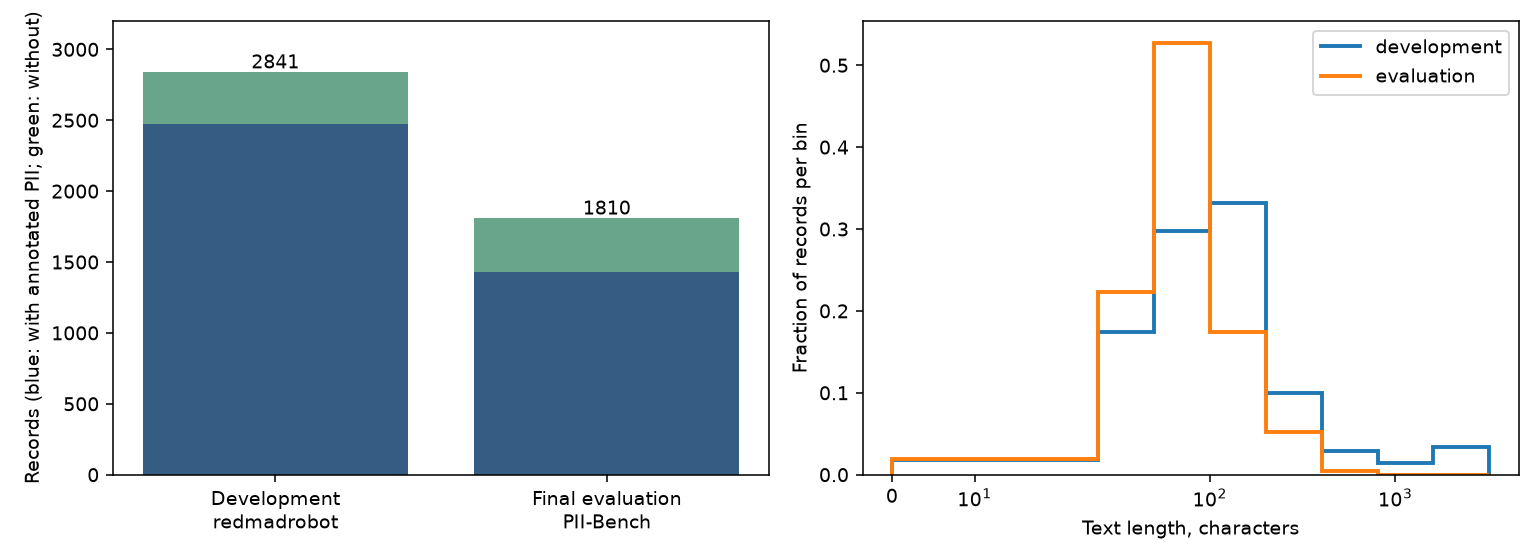

,scope,part,min,median,p95,max
0,development,all,7,102.0,741.00,2574
1,development,golden,11,106.0,732.00,2470
2,development,opt_train,7,100.0,792.25,2574
3,evaluation,all,6,70.5,214.55,520
4,evaluation,domain,6,79.0,332.00,520
5,evaluation,entity,20,63.0,158.55,238


In [4]:
display(Image(filename=str(ROOT / "eda/figures/sources_and_lengths.png")))
display(pd.DataFrame(tables["lengths"]))

Медиана длины текста в development — 102 символа против 70,5 в eval
95-й перцентиль — 741 против 214,55

## 2. Целостность разметки и отрицательные примеры

Нормализатор проверяет хеши исходников, непустой текст, структуру разметки, границы и
непересечение спанов. При возникновении ошибки подготовка данных останавливается.

In [6]:
corrections = json.loads((ROOT / "eda/development_corrections.json").read_text())
display(pd.DataFrame(corrections["corrections"]))
negative_diagnostics = []
for name, records in parts.items():
    negative = [row for row in records if not row["entities"]]
    negative_diagnostics.append(
        {
            "part": name,
            "negative_records": len(negative),
            "negative_with_digits": sum(any(c.isdigit() for c in row["text"]) for row in negative),
            "multiple_entities": sum(len(row["entities"]) > 1 for row in records),
            "max_entities": max(len(row["entities"]) for row in records),
        }
    )
display(pd.DataFrame(negative_diagnostics))

,end,kind,original_id,original_token,source,start,surface,token_index,tag
0,122.0,case_insensitive_alignment,row_0,WWW,redmadrobot,119.0,www,31,NaN
1,NaN,omit_empty_O_token_in_derived_alignment,row_1431,,redmadrobot,NaN,NaN,6,O
2,118.0,case_insensitive_alignment,row_1628,WWW,redmadrobot,115.0,www,26,NaN


,part,negative_records,negative_with_digits,multiple_entities,max_entities
0,opt_train,260,190,940,79
1,golden,111,88,398,65


Найдены три известные особенности выравнивания: два случая `WWW` в
токенах против `www` в тексте и один пустой токен с меткой `O`. Исправлено только
производное выравнивание, исходный текст и исходная BIO-разметка сохранены.

В датасете redmadrobot 371 текст без размеченных сущностей. Числа в отрицательных примерах
полезны для проверки ложных срабатываний regex.

## 3. Различия схем разметки в датасетах 

В рамках данного репозитория остаются 13 целевых типов ПД, взятые из PII-Bench. Названия трех меток унифицированы без изменения выделенных фрагментов. Различия в разметке имен, адресов и паспортов пока сохранены. Но если объединять redmadrobot и pii_bech, то и эти различия нужно будет унифицировать. 

,target,development_native_types,status
0,NAME,"FIRST_NAME,LAST_NAME,MIDDLE_NAME",different_granularity
1,ADDRESS,"COUNTRY,REGION,DISTRICT,CITY,STREET,HOUSE",different_granularity
2,PHONE,PHONE,compatible
3,EMAIL,EMAIL,compatible
4,CREDIT_CARD,CREDIT_CARD,compatible
5,PASSPORT,PASSPORT,different_granularity
6,INN,INN,compatible
7,SNILS,SNILS,compatible
8,CVC,,absent
9,KPP,,absent


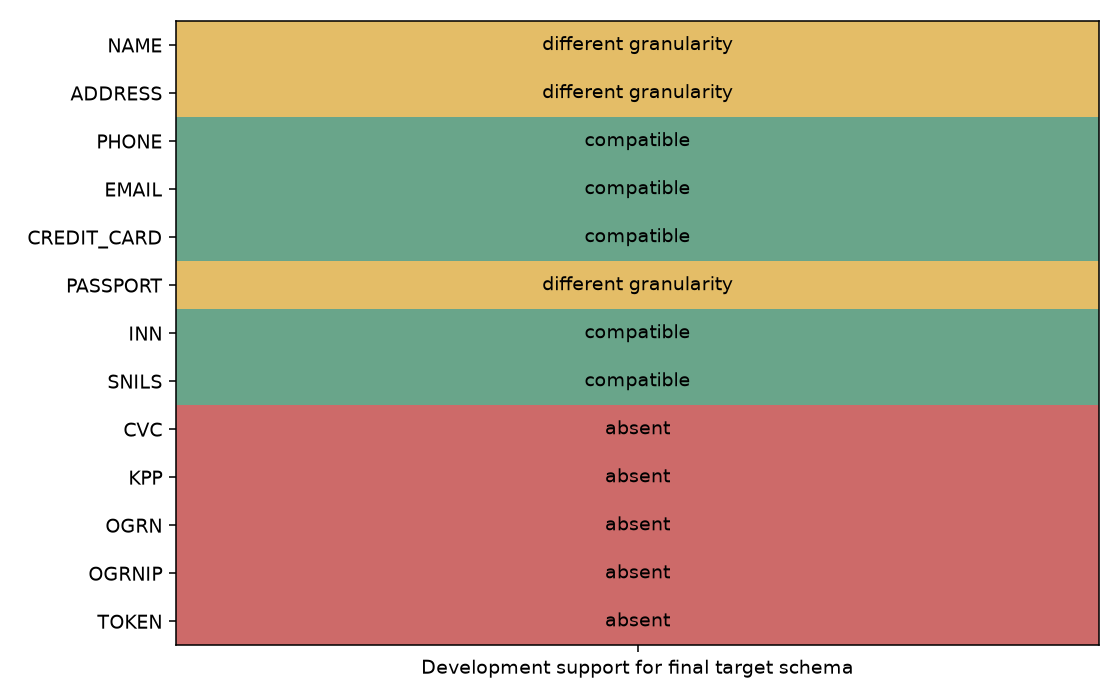

In [7]:
coverage = pd.DataFrame(tables["target_coverage"])
display(coverage[["target", "development_native_types", "status"]])
display(Image(filename=str(ROOT / "eda/figures/target_coverage.png")))

Для CVC, KPP, OGRN, OGRNIP и TOKEN данных в датасете redmadrobot (development часть) нет. NAME и ADDRESS
размечены по компонентам, PASSPORT может быть разбит на серию и номер. Эти три типа сущностей
требуют проверки и согласования гранулярности.
Для PHONE, EMAIL, CREDIT_CARD, INN и SNILS границы 
совместимы

## 4. Дубликаты, шаблоны и новое разбиение

Перед разделением данных мы объединяем похожие сообщения в группы. Учитываем совпадения текста без различий в регистре и лишних пробелах, а также совпадения после замены размеченных ПД на метки типов. Например, сообщения, отличающиеся только номером телефона, попадут в одну группу.

Для шаблонов длиной от 30 символов дополнительно проверяем близость формулировок по общим последовательностям из пяти символов: используем коэффициент Jaccard'a с порогом 0,85. Если сообщение связано совпадениями с несколькими другими, они объединяются в одну группу.

Каждая группа целиком попадает либо в opt_train, либо в golden. Это снижает риск того, что почти одинаковые примеры окажутся одновременно в данных разработки и проверки.

Алгоритм стремится сохранить пропорцию 70/30 и похожее распределение типов ПД, но не разделяет группы ради точного размера выборок. Для воспроизводимости разбиения зафиксирован seed 42.

In [8]:
display(pd.Series(summaries["development"]["checks"]["grouping"], name="Grouping audit"))
display(
    pd.DataFrame(
        [
            {"part": name, "records": len(records), "groups": len({r["group_id"] for r in records})}
            for name, records in parts.items()
        ]
    )
)
assert not ({r["group_id"] for r in parts["opt_train"]} & {r["group_id"] for r in parts["golden"]})
display(pd.Series(json.loads((ROOT / "eda/overlap_audit.json").read_text())))

algorithm                         grouped_masked_char5_jaccard_0.85_balanced_v1
groups                                                                     2687
largest_group                                                                10
matched_edges                     {'masked_template': 143, 'near_template': 11}
multi_record_groups                                                         113
records_in_multi_record_groups                                              267
semantic_independence_verified                                            False
Name: Grouping audit, dtype: object

,part,records,groups
0,opt_train,1978,1855
1,golden,863,832


interpretation                         Source overlap audit only. Zero heuristic matches does not pr...
masked_template_cross_source_groups                                                                   0
method                                                    grouped_masked_char5_jaccard_0.85_balanced_v1
near_template_cross_source_groups                                                                     0
normalized_text_cross_source_groups                                                                   0
semantic_independence_verified                                                                    False
dtype: object

После проверки 2 841 текста выделено 2 687 групп. В 113 группах оказалось по несколько похожих сообщений — всего 267 текстов. Самая большая группа содержит 10 сообщений.

Группы целиком распределены между opt_train — 1 978 текстов — и golden — 863 текста. Между выборками нет общих ID, совпадающих после нормализации текстов или сообщений из одной группы.

Отдельная проверка redmadrobot и PII-Bench также не обнаружила совпадений по выбранным правилам сравнения. Это снижает риск утечки через похожие примеры, но не гарантирует отсутствия всех смысловых повторов.


## 5. Баланс классов и сценарии

Для каждого типа ПД сравниваем, в какой доле сообщений он встречается в opt_train и golden. Доли позволяют корректно сравнить выборки разного размера: большее число сущностей в opt_train само по себе не означает дисбаланс.

Отдельно проверяем, есть ли в датасетах разметка сценариев общения и какие ситуации она охватывает: банковские обращения, доставку, обычную переписку и т.д. 

In [9]:
label_rows = pd.DataFrame(tables["label_distribution"])
dev_labels = label_rows.query("scope == 'development' and part != 'all'").copy()
part_sizes = composition.query("scope == 'development' and part != 'all'").set_index("part")[
    "records"
]
dev_labels["message_rate"] = dev_labels["positive_records"] / dev_labels["part"].map(part_sizes)
rates = dev_labels.pivot(index="label", columns="part", values="message_rate")
rates["absolute_gap"] = (rates["opt_train"] - rates["golden"]).abs()
display(rates.sort_values("absolute_gap", ascending=False).head(10).round(4))
display(pd.DataFrame(tables["domains"]).query("scope == 'evaluation' and part == 'domain'"))

part,golden,opt_train,absolute_gap
label,,,
FIRST_NAME,0.1333,0.1370,0.0038
LAST_NAME,0.1101,0.1138,0.0037
PASSPORT,0.0950,0.0976,0.0026
CREDIT_CARD,0.0672,0.0693,0.0021
COUNTRY,0.0603,0.0622,0.0019
REGION,0.0533,0.0551,0.0018
INN,0.0892,0.0910,0.0018
CITY,0.0892,0.0910,0.0018
MIDDLE_NAME,0.0973,0.0991,0.0018


,scope,part,domain,records
25,evaluation,domain,L-CHAT,100
26,evaluation,domain,L-DIALOG,100
27,evaluation,domain,S-AUTO,100
28,evaluation,domain,S-BANK,100
29,evaluation,domain,S-DELIVERY,100
30,evaluation,domain,S-HR,100
31,evaluation,domain,S-RE,100
32,evaluation,domain,S-SUPPORT,100
33,evaluation,domain,S-TELECOM,100


![Распределение спанов](../eda/figures/development_labels.png)

![Доли сообщений по типам](../eda/figures/split_label_rates.png)

Все 21 исходный тип ПД из redmadrobot встречаются и в opt_train, и в golden. Качество детектора нужно оценивать отдельно по каждому типу: общая метрика может скрыть ошибки на редких классах. Для оценки неопределённости нужны доверительные интервалы. При их расчёте важно учитывать, что части одного имени в сообщении связаны между собой и не являются независимыми примерами.

В redmadrobot не указаны сценарии общения, поэтому по нему пока нельзя отдельно оценить качество на чувствительных обращениях (S) и обычной переписке (L). Девять размеченных сценариев есть в PII-Bench/domain. В PII-Bench/entity поле domain обозначает тип сущности, а не сценарий.

Для такой проверки нужен domain: в нём 378 из 900 сообщений не содержат размеченных ПД. Результаты двух срезов следует показывать отдельно, поскольку состав примеров в них различается.
![Состав оценки](../eda/figures/evaluation_composition.png)

Во всех 910 сообщениях из entity есть размеченные ПД. Этот срез подходит для проверки распознавания разных типов сущностей, но не показывает, насколько часто детектор ставит лишние маски в текстах без ПД.

## 6. Достаточно ли данных и следующий этап

In [10]:
display(
    coverage[
        [
            "target",
            "opt_train_compatible_spans",
            "golden_compatible_spans",
            "opt_train_additional_spans",
            "golden_additional_spans",
        ]
    ]
)
display(coverage[["opt_train_additional_spans", "golden_additional_spans"]].sum())

,target,opt_train_compatible_spans,golden_compatible_spans,opt_train_additional_spans,golden_additional_spans
0,NAME,0,0,200,100
1,ADDRESS,0,0,200,100
2,PHONE,116,57,84,43
3,EMAIL,173,48,27,52
4,CREDIT_CARD,141,62,59,38
5,PASSPORT,0,0,200,100
6,INN,184,79,16,21
7,SNILS,156,67,44,33
8,CVC,0,0,200,100
9,KPP,0,0,200,100


opt_train_additional_spans    1830
golden_additional_spans        987
dtype: int64

 Чтобы достичь выбранного минимального объема данных по каждому типу, предварительно нужно добавить 1 830 размеченных сущностей в opt_train и 987 — в golden. Всего — 2 817:

- 1 500 — для пяти типов ПД, которых сейчас нет в данных разработки
- 900 — для имён, адресов и паспортов, у которых различаются правила выделения границ. Часть этого дефицита можно закрыть переразметкой существующих текстов
- 417 — для пополнения остальных пяти типов

Это количество сущностей, а не обязательно новых сообщений: один текст может содержать несколько сущностей.

Новые тексты нужно создавать без использования примеров PII-Bench: разрабатывать собственные сценарии и подставлять в них синтетические значения ПД. Для golden нужны отдельные шаблоны, которые не используются в opt_train.

Генерация данных, переразметка и обучение относятся к следующим этапам и пока не выполнены

## 7. Что установлено и что пока не проверено

- Подготовка и разбиение воспроизводимы, исходная разметка сохранена.
- Готова база EDA и предварительного исследования на redmadrobot
- Для эксперимента со всеми 13 типами требуется пополнение и полная унификация разметки

Воспроизведение: [data/README.md](../data/README.md)